In [414]:
import hashlib
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt

SEED = 1
SALT = 'some_test_1'


# синтетический A/B тест

Для теста берется группа клиентов участвующих в акции,  
для контрольной группы берутся те же клиенты до начала акции  
оба набора сопоставляются как будто для одной группы клиентов включили акцию, а для другой нет  

группа A - пользователи которые участвуют в акции 8 за 49 дней до ее проведения  
группа B - пользователи участвующие в акции 8, которая длится 49 дней

главный показатель - среднее количество акционных товаров, продаваемых в день за выбранный промежуток времени

Нулевая гипотеза H0:  акция ничего не меняет продажи не зависят от наличия акции  
Альтернативная гипотеза H1: изменение не равно нулю

In [415]:
td = pd.read_csv(r'../datasets/transaction_data.csv')
td = td[td['SALES_VALUE']>0]
campaign_desc = pd.read_csv(r'../datasets/campaign_desc.csv')
campaign_table = pd.read_csv(r'../datasets/campaign_table.csv')
coupon = pd.read_csv(r'../datasets/coupon.csv')


выбор номера компании:  

In [416]:
i_comp = 8


выделение пользователей, участвующих в нужной акционной компани:  


In [417]:
mask = campaign_table['CAMPAIGN'] == i_comp
comp_users = campaign_table['household_key'][mask].tolist()
print('количество участников акции:', len(comp_users))

количество участников акции: 1076


выделение товаров участвующих в акции:  


In [418]:
p_mask = coupon['CAMPAIGN'] == i_comp
comp_products = coupon['PRODUCT_ID'][p_mask].unique().tolist()
print('количество акционных товаров:', len(comp_products))

количество акционных товаров: 17178


вывод временных параметров акции: дня старта акции, дня окончания, продолжительности акции:   

In [419]:
c_mask = campaign_desc['CAMPAIGN'] == i_comp
d_start = campaign_desc['START_DAY'][c_mask].values[0]
d_end = campaign_desc['END_DAY'][c_mask].values[0]
n_days = (d_end - d_start) + 1

кампания 8  
начинается с 412 дня, заканчивается после 460 дня  
длительность акции составляет 49 дней  

ниже сначали считается сумма количества всех акционных товаров в одном чеке    
затем ищется среднее количество проданных акционных товаров на чек за день  

In [420]:
cond_1 = td['DAY'] >= d_start - n_days
cond_2 = td['DAY'] <= d_start - 1

control = td[cond_1 & cond_2].copy()
control = control[control['household_key'].isin(comp_users)].copy()
control = control[control['PRODUCT_ID'].isin(comp_products)].copy()
control_s = control.copy()
control = control.groupby(['DAY', 'BASKET_ID'], as_index=False)['QUANTITY'].sum()
control = control.groupby(['DAY'], as_index=False)['QUANTITY'].mean()

cond_3 = td['DAY'] >= d_start
cond_4 = td['DAY'] <= d_end

treatment = td[cond_3 & cond_4].copy()
treatment = treatment[treatment['household_key'].isin(comp_users)].copy()
treatment = treatment[treatment['PRODUCT_ID'].isin(comp_products)].copy()
treatment_s = treatment.copy()
treatment = treatment.groupby(['DAY', 'BASKET_ID'], as_index=False)['QUANTITY'].sum()
treatment = treatment.groupby(['DAY'], as_index=False)['QUANTITY'].mean()

если считать что наблюдение делалось параллельно для одиноковых групп, то :

In [421]:
print('количество пользователей группы A совершавших покупки:', len(control_s['household_key'].unique()))
print('количество пользователей группы A не делавших покупок:', len(comp_users) - len(control_s['household_key'].unique()))
print('количество уникальных товаров купленных группой A:', len(control_s['PRODUCT_ID'].unique()))
print('\n')
print('количество пользователей группы B совершавших покупки:', len(treatment_s['household_key'].unique()))
print('количество пользователей группы B не делавших покупок:', len(comp_users) - len(treatment_s['household_key'].unique()))
print('количество уникальных товаров купленных группой B:', len(treatment_s['PRODUCT_ID'].unique()))

количество пользователей группы A совершавших покупки: 1047
количество пользователей группы A не делавших покупок: 29
количество уникальных товаров купленных группой A: 5489


количество пользователей группы B совершавших покупки: 1033
количество пользователей группы B не делавших покупок: 43
количество уникальных товаров купленных группой B: 5566


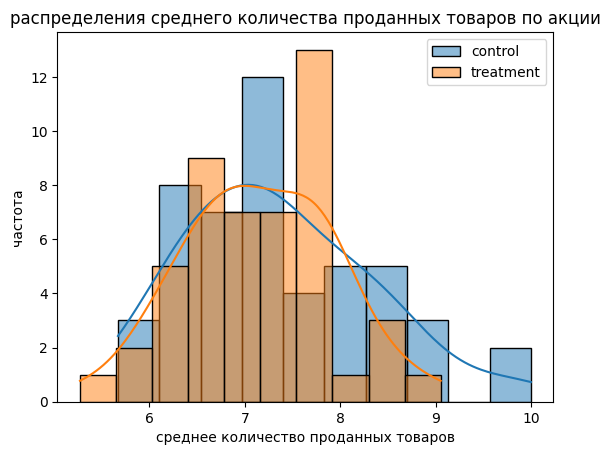

In [422]:
sns.histplot(control['QUANTITY'], bins=10, kde=True, label='control')
sns.histplot(treatment['QUANTITY'], bins=10, kde=True, label='treatment')

plt.legend()
plt.xlabel('среднее количество проданных товаров')
plt.ylabel('частота')
plt.title('распределения среднего количества проданных товаров по акции')
plt.show()

t-test: проверка равенства средних метрик

In [423]:
ALPHA = 0.05

t_stat, p_value = stats.ttest_ind(treatment['QUANTITY'], control['QUANTITY'], alternative='two-sided')
print('t-статистика:', t_stat)
print('p-value:', p_value)

t-статистика: -1.1015506847241583
p-value: 0.27341122368152204


p-value > 0.05 значит мы не можем отвергнуть нулевую гипотезу (различий в группе не достаточно, чтобы говорить о значимом отличии групп)

Ранговая проверка Манна—Уитни

In [424]:
a = stats.mannwhitneyu(treatment['QUANTITY'], control['QUANTITY'], alternative='two-sided', method='asymptotic', use_continuity=True)
 
print('статистика:', a.statistic)
print('p-value:', a.pvalue)

статистика: 1084.0
p-value: 0.4098234206321346


аналогичныый вывод и для теста Манна-Уитни, нет оснований отвергать нулевую гипотезу

Вывод: нет статистически значимых изменений, чтобы говорить о влиянии 8 акции на продажи товаров 

# синтетический A/B тест 2

Все предположения те же что и для первого случая, только теперь возмем периоды по 40 недель и будем сравнивать сумму чеков за эти периды  

группа A - пользователи которые участвуют в акции с 21 по 60 недели  
группа B - пользователи участвующие в акции с 61 по 100 недели  

главный показатель - чек покупок

Нулевая гипотеза H0: акции ничего не меняют, чеки до и после одинаковые   
Альтернативная гипотеза H1: изменение не равно нулю  

In [425]:
cond_1 = td['WEEK_NO'] >= 21
cond_2 = td['WEEK_NO'] <= 60

control = td[cond_1 & cond_2].copy()
control_s = control.copy()
control = control.groupby(['BASKET_ID'], as_index=False)['SALES_VALUE'].sum()

cond_3 = td['WEEK_NO'] >= 61
cond_4 = td['WEEK_NO'] <= 100

treatment = td[cond_3 & cond_4].copy()
treatment_s = treatment.copy()
treatment = treatment.groupby(['BASKET_ID'], as_index=False)['SALES_VALUE'].sum()

In [426]:
def outlier_remover(data1, data2, col_name, x_quantile=0.95, two_side=False):
    if two_side==False:
        dt_1 = data1[data1[col_name] <= data1[col_name].quantile(x_quantile)]
        dt_2 = data2[data2[col_name] <= data2[col_name].quantile(x_quantile)]
    else:
        c1 = data1[col_name] <= data1[col_name].quantile(x_quantile)
        c2 = data1[col_name] >= data1[col_name].quantile(1 - x_quantile)
        dt_1 = data1[c1 & c2]

        c3 = data2[col_name] <= data2[col_name].quantile(x_quantile)
        c4 = data2[col_name] >= data2[col_name].quantile(1 - x_quantile)
        dt_2 = data2[c3 & c4]

    return dt_1, dt_2 

оставляю чеки, у которых сумма находится между 1 и 99 персентилями

In [427]:
control, treatment = outlier_remover(control, treatment, 'SALES_VALUE', 0.99, True)

логариф сум чеков используется только для построения графиков

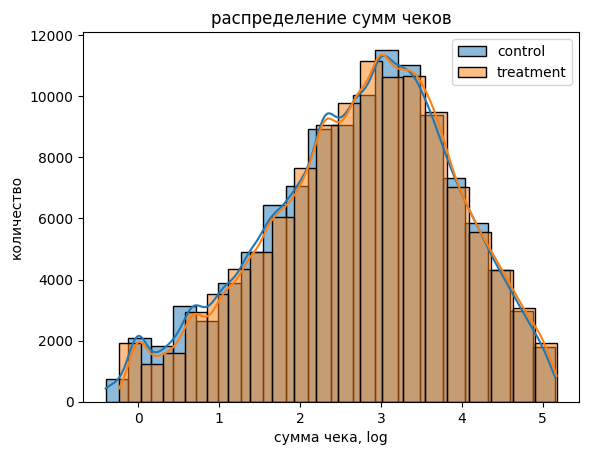

In [428]:
sns.histplot(np.log(control['SALES_VALUE']), bins=20, kde=True, label='control')
sns.histplot(np.log(treatment['SALES_VALUE']), bins=20, kde=True, label='treatment')

plt.legend()
plt.xlabel('сумма чека, log')
plt.ylabel('количество')
plt.title('распределение сумм чеков')
plt.show()

In [429]:
t_stat, p_value = stats.ttest_ind(treatment['SALES_VALUE'], control['SALES_VALUE'], alternative='two-sided')
print('t-статистика:', t_stat)
print('p-value:', p_value)
if p_value <= ALPHA:
    print('отвергаем нулевую гипотезу')
else:
    print('нет оснований отвергнуть нулевую гипотезу')

t-статистика: 8.659375900500162
p-value: 4.773152615988024e-18
отвергаем нулевую гипотезу


In [430]:
a = stats.mannwhitneyu(treatment['SALES_VALUE'], control['SALES_VALUE'], alternative='two-sided', use_continuity=True)
 
print('статистика:', a.statistic)
print('p-value:', a.pvalue)
if a.pvalue <= ALPHA:
    print('отвергаем нулевую гипотезу')
else:
    print('нет оснований отвергнуть нулевую гипотезу')

статистика: 6879170862.5
p-value: 9.784691434492425e-24
отвергаем нулевую гипотезу


Bootstrap: 
- n раз независимо выбираем с возвращением $n_A$ чеков из A группы и $n_B$ чеков из B группы
- в каждой подвыборке считаем средние и находим разницу средних: $\mu_B - \mu_A$
- строим доверительный интервал и смотрим на распределение разниц средних


In [431]:
np.random.seed(SEED)

n_iter = 5000
dif_mean = np.zeros(n_iter)
n_a, n_b = len(control['SALES_VALUE']), len(treatment['SALES_VALUE'])

for i in range(n_iter):
    a_idx = np.random.choice(control['SALES_VALUE'].index, n_a, replace=True)
    b_idx = np.random.choice(treatment['SALES_VALUE'].index, n_b, replace=True)
    a_mean = control['SALES_VALUE'][a_idx].mean()
    b_mean = treatment['SALES_VALUE'][b_idx].mean()
    dif_mean[i] = b_mean - a_mean

boot_ci = np.quantile(dif_mean, [ALPHA / 2, 1 - ALPHA / 2])

Средний чек в группе B примерно на 1,4 единицы выше чем в контрольной группе.  
границы доверительного интервала разниц: [1,00; 1,84]  
доверительный интервал не включает ноль, значит можно сказать, что наблюдается статистически значимый более высокий средний чек в группе В

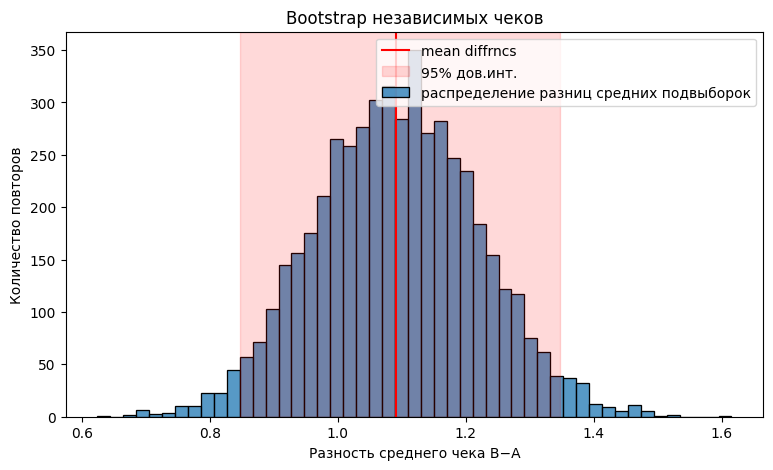

In [432]:
fig, ax = plt.subplots(figsize=(9,5))
sns.histplot(dif_mean, label='распределение разниц средних подвыборок')
plt.axvline(treatment['SALES_VALUE'].mean()-control['SALES_VALUE'].mean(), color='r', label='mean diffrncs')
plt.axvspan(boot_ci[0], boot_ci[1], color='r', alpha=0.15, label='95% дов.инт.')

plt.title('Bootstrap независимых чеков')
plt.xlabel('Разность среднего чека B−A')
plt.ylabel('Количество повторов')
plt.legend()
plt.show()

хеширование и salt

разделение пользователей по группам

In [433]:
mask = (td['WEEK_NO'] >= 21) & (td['WEEK_NO'] <= 100)
comp_users = td['household_key'][mask].unique()
print('количество участников акции:', len(comp_users))

количество участников акции: 2491


SHA-256 от соли и id пользователя задает воспроизводимые группы

In [434]:
user_keys = [f'{SALT}+{i}' for i in comp_users]
user_hashes = [hashlib.sha256(i.encode('utf-8')).hexdigest() for i in user_keys]
a_group = np.array([int(i, 16) % 2 for i in user_hashes])
b_users, a_users = comp_users[a_group == 0], comp_users[a_group == 1]

In [435]:
cond_1 = td['WEEK_NO'] >= 21
cond_2 = td['WEEK_NO'] <= 60
cond_3 = td['household_key'].isin(a_users)

control = td[cond_1 & cond_2 & cond_3].copy()
control_s = control.copy()
control = control.groupby(['household_key','BASKET_ID'], as_index=False)['SALES_VALUE'].sum()

cond_4 = td['WEEK_NO'] >= 61
cond_5 = td['WEEK_NO'] <= 100
cond_6 = td['household_key'].isin(b_users)

treatment = td[cond_4 & cond_5 & cond_6].copy()
treatment_s = treatment.copy()
treatment = treatment.groupby(['household_key','BASKET_ID'], as_index=False)['SALES_VALUE'].sum()

control, treatment = outlier_remover(control, treatment, 'SALES_VALUE', 0.99, True)

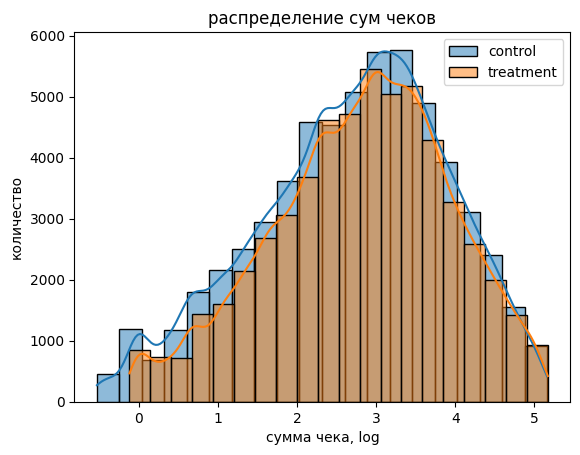

In [436]:
sns.histplot(np.log(control['SALES_VALUE']), bins=20, kde=True, label='control')
sns.histplot(np.log(treatment['SALES_VALUE']), bins=20, kde=True, label='treatment')

plt.legend()
plt.xlabel('сумма чека, log')
plt.ylabel('количество')
plt.title('распределение сум чеков')
plt.show()

In [437]:
t_stat, p_value = stats.ttest_ind(treatment['SALES_VALUE'], control['SALES_VALUE'], alternative='two-sided')
print('t-статистика:', t_stat)
print('p-value:', p_value)
if p_value <= ALPHA:
    print('отвергаем нулевую гипотезу')
else:
    print('нет оснований отвергнуть нулевую гипотезу')

t-статистика: 8.436018992376907
p-value: 3.320527237835063e-17
отвергаем нулевую гипотезу


In [438]:
a = stats.mannwhitneyu(treatment['SALES_VALUE'], control['SALES_VALUE'], alternative='two-sided', use_continuity=True)
 
print('статистика:', a.statistic)
print('p-value:', a.pvalue)
if a.pvalue <= ALPHA:
    print('отвергаем нулевую гипотезу')
else:
    print('нет оснований отвергнуть нулевую гипотезу')

статистика: 1737562542.5
p-value: 1.4998958832765395e-39
отвергаем нулевую гипотезу
